# ============================================================
# NETGUARD AI
# Notebook 08 - Autoencoder Analysis
# ============================================================

"""
Objective:
Use an Autoencoder to learn a compact representation
of network traffic features.

Scientific Question:
Can the Autoencoder compress the selected network-flow
features while preserving important information?
"""

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

In [2]:
df = pd.read_csv("netguard_selected_features.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (223082, 21)


,Fwd Packet Length Max,Destination Port,Bwd Packet Length Min,Init_Win_bytes_forward,Subflow Fwd Bytes,act_data_pkt_fwd,Fwd IAT Std,Fwd IAT Mean,Subflow Fwd Packets,Bwd Packet Length Std,...,Bwd IAT Total,Bwd IAT Max,Bwd IAT Mean,Bwd Packets/s,Average Packet Size,min_seg_size_forward,Packet Length Variance,Fwd Packet Length Min,Min Packet Length,Label
0,6,54865,0,33,12,1,0.0,3.0,2,0.0,...,0,0,0.0,0.000000,9.0,20,0.0,6,6,BENIGN
1,6,55054,6,29,6,0,0.0,0.0,1,0.0,...,0,0,0.0,9174.311927,9.0,20,0.0,6,6,BENIGN
2,6,55055,6,29,6,0,0.0,0.0,1,0.0,...,0,0,0.0,19230.769230,9.0,20,0.0,6,6,BENIGN
3,6,46236,6,31,6,0,0.0,0.0,1,0.0,...,0,0,0.0,29411.764710,9.0,20,0.0,6,6,BENIGN
4,6,54863,0,32,12,1,0.0,3.0,2,0.0,...,0,0,0.0,0.000000,9.0,20,0.0,6,6,BENIGN


In [3]:
X = df.drop("Label", axis=1)

y = df["Label"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (223082, 20)
Target shape: (223082,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 178465
Testing samples : 44617


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape :", X_test_scaled.shape)

Scaled training shape: (178465, 20)
Scaled testing shape : (44617, 20)


Input

  ↓

32 neurons

  ↓

16 neurons

  ↓

32 neurons

  ↓
  
Output

In [6]:
input_dim = X_train_scaled.shape[1]

input_layer = Input(shape=(input_dim,))

# Encoder
encoded = Dense(
    32,
    activation="relu"
)(input_layer)

latent = Dense(
    16,
    activation="relu",
    name="latent_space"
)(encoded)

# Decoder
decoded = Dense(
    32,
    activation="relu"
)(latent)

output_layer = Dense(
    input_dim,
    activation="linear"
)(decoded)

autoencoder = Model(
    input_layer,
    output_layer
)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_space (Dense)            │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 20)             │           660 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,404 (9.39 KB)

 Trainable params: 2,404 (9.39 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

In [8]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [9]:
history = autoencoder.fit(
    X_train_scaled,
    X_train_scaled,
    epochs=50,
    batch_size=256,
    validation_split=0.2,
    callbacks=[early_stopping],
    shuffle=True,
    verbose=1
)

Epoch 1/50
558/558 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.2873 - val_loss: 0.0730
Epoch 2/50
558/558 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0422 - val_loss: 0.0290
Epoch 3/50
558/558 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0239 - val_loss: 0.0215
Epoch 4/50
558/558 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0181 - val_loss: 0.0171
Epoch 5/50
558/558 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0155 - val_loss: 0.0132
Epoch 6/50
558/558 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0121 - val_loss: 0.0115
Epoch 7/50
558/558 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0115 - val_loss: 0.0094
Epoch 8/50
558/558 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0080 - val_loss: 0.0068
Epoch 9/50
558/558 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0079 - val_loss: 0.0062
Epoch 10/50
558/558 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0060 - val_loss: 0.0052
Epoch 11/50
558/558 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0062 - val_loss: 0.0053
Epoch 12/50
558/558 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

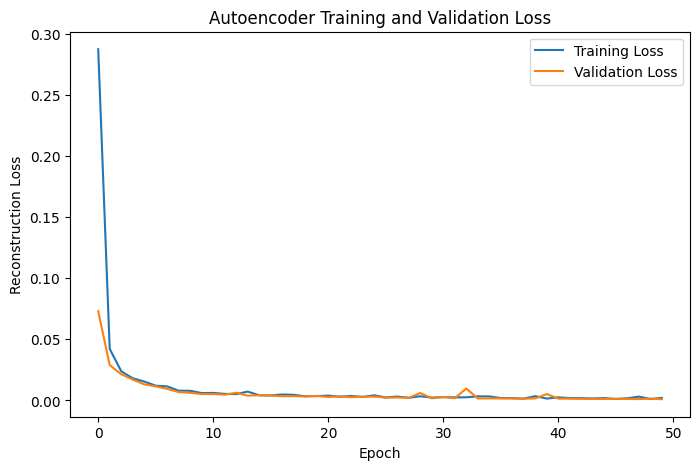

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Reconstruction Loss")
plt.title("Autoencoder Training and Validation Loss")

plt.legend()
plt.show()

If training loss continues decreasing while validation loss increases significantly, that could indicate overfitting.

In [11]:
X_test_reconstructed = autoencoder.predict(
    X_test_scaled,
    verbose=0
)

print(
    "Reconstructed shape:",
    X_test_reconstructed.shape
)
# The reconstructed data should have the same number of features as the input.

Reconstructed shape: (44617, 20)


In [12]:
reconstruction_mse = np.mean(
    np.square(
        X_test_scaled - X_test_reconstructed
    ),
    axis=1
)

print("Mean reconstruction error:",
      reconstruction_mse.mean())

print("Median reconstruction error:",
      np.median(reconstruction_mse))

print("Maximum reconstruction error:",
      reconstruction_mse.max())

Mean reconstruction error: 0.0009776622905748622
Median reconstruction error: 0.00017913748790058363
Maximum reconstruction error: 0.6586909656737082


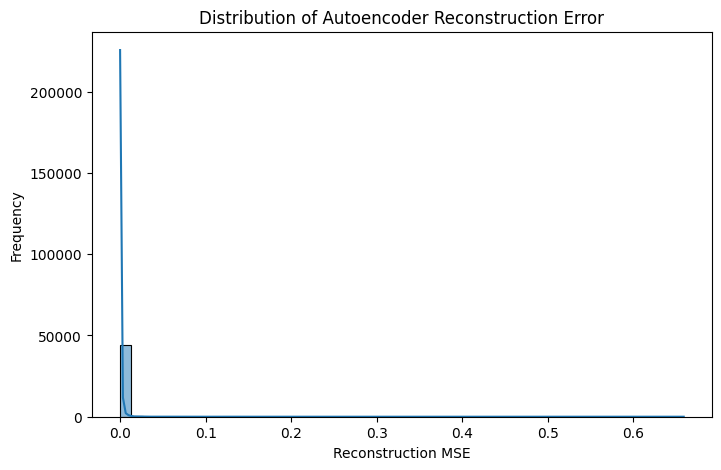

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(
    reconstruction_mse,
    bins=50,
    kde=True
)

plt.xlabel("Reconstruction MSE")
plt.ylabel("Frequency")
plt.title("Distribution of Autoencoder Reconstruction Error")

plt.show()
# This shows how well the Autoencoder reconstructs the network traffic.

In [ ]:
error_df = pd.DataFrame({
    "Label": y_test.values,
    "Reconstruction_Error": reconstruction_mse
})

error_df.groupby("Label")["Reconstruction_Error"].agg(
    ["mean", "median", "std", "min", "max"]
)
# Do BENIGN and DDoS traffic have different reconstruction-error distributions?

Object `distributions` not found.


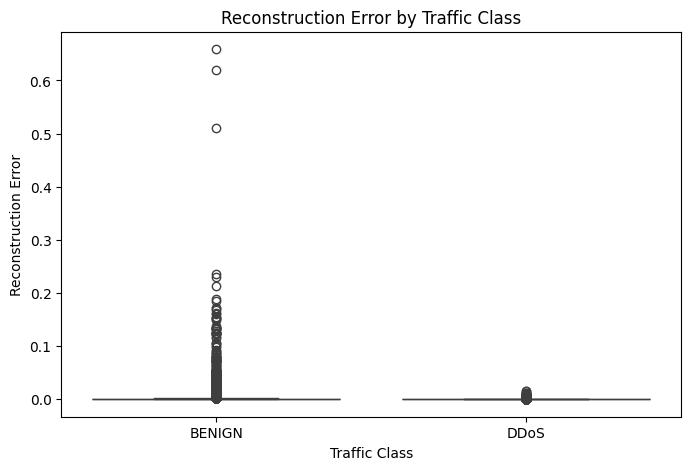

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=error_df,
    x="Label",
    y="Reconstruction_Error"
)

plt.xlabel("Traffic Class")
plt.ylabel("Reconstruction Error")
plt.title("Reconstruction Error by Traffic Class")

plt.show()

If DDoS traffic has systematically different reconstruction errors, that suggests the Autoencoder has learned a representation that captures differences between traffic patterns.

But don't claim:

"The Autoencoder detects DDoS."

yet.

At this stage, we are only analyzing the learned representation.

In [16]:
encoder = Model(
    inputs=autoencoder.input,
    outputs=autoencoder.get_layer("latent_space").output
)

In [17]:
X_train_encoded = encoder.predict(
    X_train_scaled,
    verbose=0
)

X_test_encoded = encoder.predict(
    X_test_scaled,
    verbose=0
)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape :", X_test_encoded.shape)

Encoded training shape: (178465, 16)
Encoded testing shape : (44617, 16)


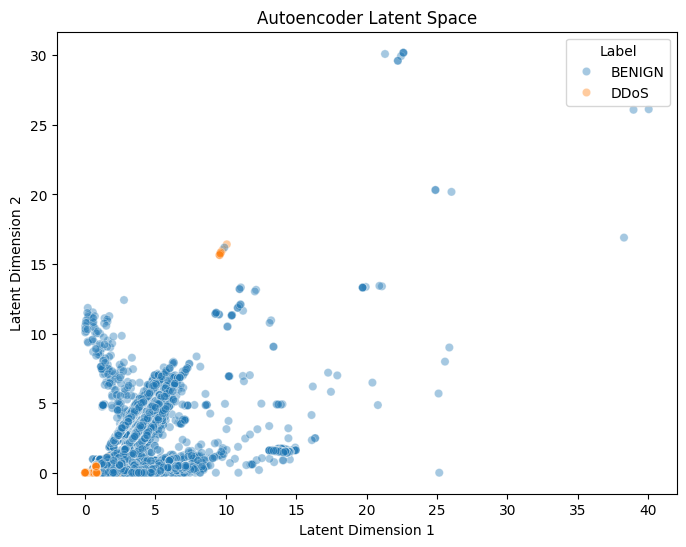

In [18]:
latent_df = pd.DataFrame({
    "Latent_1": X_test_encoded[:, 0],
    "Latent_2": X_test_encoded[:, 1],
    "Label": y_test.values
})

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=latent_df,
    x="Latent_1",
    y="Latent_2",
    hue="Label",
    alpha=0.4
)

plt.title("Autoencoder Latent Space")
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")

plt.show()

In [19]:
# Compare Reconstruction Error by Class
class_error = (
    error_df
    .groupby("Label")["Reconstruction_Error"]
    .mean()
    .sort_values(ascending=False)
)

print(class_error)

Label
BENIGN    0.002018
DDoS      0.000205
Name: Reconstruction_Error, dtype: float64


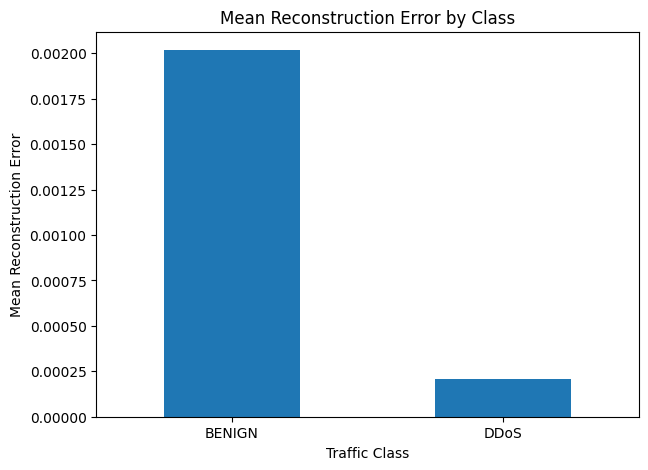

In [20]:
plt.figure(figsize=(7, 5))

class_error.plot(
    kind="bar"
)

plt.ylabel("Mean Reconstruction Error")
plt.xlabel("Traffic Class")
plt.title("Mean Reconstruction Error by Class")

plt.xticks(rotation=0)

plt.show()

In [21]:
# Save Encoded Features
encoded_train_df = pd.DataFrame(
    X_train_encoded,
    columns=[f"Latent_{i+1}" for i in range(X_train_encoded.shape[1])]
)

encoded_test_df = pd.DataFrame(
    X_test_encoded,
    columns=[f"Latent_{i+1}" for i in range(X_test_encoded.shape[1])]
)

encoded_train_df["Label"] = y_train.reset_index(drop=True)

encoded_test_df["Label"] = y_test.reset_index(drop=True)

In [22]:
encoded_train_df.to_csv(
    "autoencoder_encoded_train.csv",
    index=False
)

encoded_test_df.to_csv(
    "autoencoder_encoded_test.csv",
    index=False
)

print("Encoded features saved successfully.")

Encoded features saved successfully.


In [23]:
error_df.to_csv(
    "autoencoder_reconstruction_errors.csv",
    index=False
)

print("Reconstruction errors saved successfully.")

Reconstruction errors saved successfully.


In [24]:
print("========== AUTOENCODER SUMMARY ==========")

print("Original feature dimensions:", input_dim)

print(
    "Latent dimensions:",
    X_train_encoded.shape[1]
)

print(
    "Compression ratio:",
    round(
        X_train_encoded.shape[1] / input_dim,
        3
    )
)

print(
    "Mean test reconstruction MSE:",
    round(reconstruction_mse.mean(), 6)
)

print("\nMean reconstruction error by class:")
print(class_error)

========== AUTOENCODER SUMMARY ==========
Original feature dimensions: 20
Latent dimensions: 16
Compression ratio: 0.8
Mean test reconstruction MSE: 0.000978

Mean reconstruction error by class:
Label
BENIGN    0.002018
DDoS      0.000205
Name: Reconstruction_Error, dtype: float64


## Conclusion

The Autoencoder successfully learned a lower-dimensional
representation of the selected network traffic features.

The original feature space was compressed into a
16-dimensional latent representation.

Reconstruction loss was monitored during training to
evaluate whether the Autoencoder could preserve the
information contained in the input features.

Reconstruction errors were also compared between BENIGN
and DDoS traffic to investigate whether the learned
representation captures differences between the two
traffic classes.

The encoded latent features will be used in the next
experiment to evaluate whether Autoencoder-based feature
representation can support DDoS classification.